# Actividad MLOps: Detección de Fraude en Tarjetas de Crédito con MLflow

**Estudiante:** Bryan Ortega  
**Materia / Código:** TC5061 - MLOps / Machine Learning en Producción  
**Base Metodológica:** Basado y extendido del libro [*Reproducible Machine Learning for Credit Card Fraud Detection - Practical Handbook*](https://fraud-detection-handbook.github.io/fraud-detection-handbook/) (Le Borgne et al. [1]).  
**Declaración de Asistencia de Inteligencia Artificial:** Para el co-diseño de la arquitectura del flujo, estructuración de pruebas unitarias, formalización taxonómica de escenarios y refinamiento analítico de código, se contó con la colaboración del modelo fundacional **Gemini 3.8 Flash** de Google DeepMind [8] en modalidad de pair-programming.

---

### Contexto y Motivación del Problema

La detección de fraude en medios de pago digitales representa uno de los retos más complejos de Machine Learning en ingeniería de producción, caracterizado por clases raras y asimetría severa de costos (Hand & Blunt [2]):
1. **Desbalance Severo de Clases:** Menos del $4\%$ de las transacciones son fraudulentas.
2. **Dinámica Adversarial y Multi-Escenario:** Los defraudadores no operan con un único patrón. Existen múltiples modalidades de ataque (desde transacciones masivas de alto monto hasta ráfagas automatizadas de micro-montos por bots y clonación geográfica).
3. **Costo Asimétrico de Decisión:** Un Falso Negativo (fraude no detectado) produce pérdidas financieras directas, contracargos y sanciones regulatorias; un Falso Positivo (bloqueo erróneo) genera fricción, llamadas al call center y pérdida de confianza del cliente legítimo.
4. **Restricciones de Latencia en Tiempo Real:** El motor de scoring debe tomar una decisión en menos de 50 milisegundos en la pasarela de pagos.

---

### Estructura de la Actividad:
- **Paso 1:** Carga y describe el dataset (estructura, tipos, registros y significado de variables).
- **Taxonomía de Fraude:** Problemática de los 6 tipos de fraude y soluciones tecnológicas/MLOps.
- **Paso 2:** Análisis exploratorio de datos (EDA) (distribuciones, correlaciones y dinámicas temporales y por escenario).
- **Paso 3:** Limpieza de datos (tratamiento documentado de nulos, duplicados, tipos y outliers).
- **Paso 4:** Entrenamiento del modelo base (baseline de Regresión Logística con split temporal).
- **Paso 5:** Evaluación rigurosa (PR-AUC, ROC-AUC, Recall, Matriz de Confusión y análisis por escenario).
- **Paso 6:** Registro del experimento en MLflow Tracking (parámetros, métricas y artefactos).
- **Paso 7:** Reflexión crítica sobre prácticas de MLOps y aplicación profesional (+150 palabras).
- **Paso 8:** Referencias y Citas Bibliográficas (formato APA).


In [1]:
# 0. Configuración del entorno y librerías necesarias
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelado y preprocesamiento con Scikit-Learn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# MLflow para tracking de experimentos y registro de artefactos
import mlflow
import mlflow.sklearn

# Módulos locales del proyecto
from src.data_generator import generate_full_dataset
from src.features import clean_transactions_data, extract_features

# Configuraciones visuales
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['font.size'] = 11

print("Entorno configurado correctamente con Pandas, Scikit-Learn y MLflow.")


2026/10/04 22:34:40 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/bryan/learning/mlops/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Entorno configurado correctamente con Pandas, Scikit-Learn y MLflow.


## Paso 1: Carga y describe el dataset

Importamos los datos simulados que modelan un ecosistema de pagos completo con:
- $1,000$ clientes con hábitos de gasto diferenciados y coordenadas geográficas.
- $1,500$ terminales de puntos de venta (POS).
- $30$ días continuos de transacciones financieras.
- **6 escenarios de fraude simulados** que cubren el espectro de amenazas modernas.


In [2]:
# Paso 1.1: Cargar el dataset desde archivo CSV (o generarlo si no existe)
data_path = 'data/transactions_simulated.csv'

if not os.path.exists(data_path):
    print("Archivo no encontrado. Generando dataset con el simulador de 6 escenarios...")
    os.makedirs('data', exist_ok=True)
    df_raw = generate_full_dataset(n_customers=1000, n_terminals=1500, nb_days=30, inject_issues=True)
    df_raw.to_csv(data_path, index=False)
    print(f"Dataset generado exitosamente en: {data_path}")
else:
    df_raw = pd.read_csv(data_path)
    print(f"Dataset cargado exitosamente desde: {data_path}")

print(f"Dimensiones del dataset cargado: {df_raw.shape[0]:,} transacciones y {df_raw.shape[1]} variables.")


Dataset cargado exitosamente desde: data/transactions_simulated.csv
Dimensiones del dataset cargado: 58,728 transacciones y 9 variables.


In [3]:
# Paso 1.2: Inspección inicial de registros
df_raw.head()


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2024-01-01 00:01:59,157.0,873,9.53,119,0,0,0
1,1,2024-01-01 00:02:29,834.0,461,82.26,149,0,0,0
2,2,2024-01-01 00:07:56,2.0,240,12.66,476,0,0,0
3,3,2024-01-01 00:10:45,568.0,821,134.96,645,0,0,0
4,4,2024-01-01 00:18:35,894.0,1134,49.23,1115,0,0,0


In [4]:
# Paso 1.3: Inspección de estructura y tipos de datos en memoria
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 58728 entries, 0 to 58727
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TRANSACTION_ID     58728 non-null  int64  
 1   TX_DATETIME        58728 non-null  str    
 2   CUSTOMER_ID        58611 non-null  float64
 3   TERMINAL_ID        58728 non-null  int64  
 4   TX_AMOUNT          58611 non-null  float64
 5   TX_TIME_SECONDS    58728 non-null  int64  
 6   TX_TIME_DAYS       58728 non-null  int64  
 7   TX_FRAUD           58728 non-null  int64  
 8   TX_FRAUD_SCENARIO  58728 non-null  int64  
dtypes: float64(2), int64(6), str(1)
memory usage: 5.1 MB


### Descripción de la estructura y significado de las variables

| Variable | Tipo en Dataset | Tipo Esperado | Significado en el Dominio de Pagos |
| :--- | :--- | :--- | :--- |
| **`TRANSACTION_ID`** | `int64` | `int64` / ID único | Identificador unívoco de la transacción en la pasarela o switch transaccional. |
| **`TX_DATETIME`** | `object` (string) | `datetime64[ns]` | Marca temporal precisa (fecha y hora) en que ocurrió la autorización del pago. |
| **`CUSTOMER_ID`** | `float64` / `int64` | `int64` (Categórico) | Identificador único del tarjeta-habiente / titular de la cuenta bancaria. |
| **`TERMINAL_ID`** | `int64` | `int64` (Categórico) | Identificador del punto de venta (POS) o comercio donde se procesó la tarjeta. |
| **`TX_AMOUNT`** | `float64` | `float64` (Continuo) | Monto monetario de la transacción en la divisa base de la operación. |
| **`TX_TIME_SECONDS`** | `int64` | `int64` (Continuo) | Tiempo transcurrido en segundos desde el inicio de la simulación. |
| **`TX_TIME_DAYS`** | `int64` | `int64` (Discreto) | Día del período transcurrido (0 a 29) desde el inicio de la ventana de datos. |
| **`TX_FRAUD`** | `int64` | `int64` (Binario) | **Variable objetivo (Target):** $0$ para transacción legítima, $1$ para fraudulenta. |
| **`TX_FRAUD_SCENARIO`** | `int64` | `int64` (Categórico) | Escenario de ataque específico (0 a 6) que originó el fraude. |


## Problemática de los Distintos Tipos de Fraude y Soluciones para Identificarlos

En la industria de pagos real, el fraude no es homogéneo. A continuación se resume la problemática específica de cada uno de los **6 escenarios simulados** y las **soluciones tecnológicas y analíticas recomendadas** para combatirlos:

| Escenario | Nombre del Fraude | Problemática y Vector de Ataque | ¿Por qué falla un modelo simple? | Solución Tecnológica / MLOps Recomendada |
| :--- | :--- | :--- | :--- | :--- |
| **Escenario 1** | **Monto Anormalmente Alto** *(High-Amount Outlier)* | El atacante intenta extraer la mayor cantidad de fondos posible en una única transacción ($> \$220$). | No falla: es detectable con reglas de umbral directo o modelos univariados. | **Reglas deterministas duras (Hard Rules)** en pasarela previas al modelo + Z-Score global del monto. |
| **Escenario 2** | **Terminal Comprometida** *(POS Malware / Skimming)* | Terminales vulneradas durante $28$ días. Toda transacción en ellas es fraudulenta sin importar el cliente ni el monto. | Un modelo baseline no evalúa la historia del comercio; ve montos normales de clientes habituales. | **Feature Store con agregaciones de terminal:** conteo de transacciones, tasa de contracargos en ventanas de 1, 7 y 28 días, y análisis de grafos de terminales. |
| **Escenario 3** | **Robo de Credenciales / CNP** *(Account Takeover)* | Tarjeta comprometida durante $14$ días. El atacante hace compras quintuplicando el monto promedio del cliente. | Si el cliente suele gastar poco, un monto de $\$50$ puede ser fraude para él pero normal para el banco global. | **Profiling individualizado del cliente:** features relativas como $\frac{\text{monto\_actual}}{\text{promedio\_30días\_cliente}}$, y modelos de detección de anomalías (Isolation Forest, Autoencoders). |
| **Escenario 4** | **Card Testing / Card Busting** *(Micro-transacciones en ráfaga)* | Bots prueban tarjetas robadas haciendo de $4$ a $7$ transacciones de montos diminutos ($\$0.50$ a $\$2.50$) en segundos. | **Falla catastróficamente:** los modelos entrenados con montos altos clasifican micro-montos como 'seguros'. | **Sliding Velocity Counters en Streaming (Apache Flink / Kafka):** conteo de intentos por tarjeta en ventanas de $60$ segundos, rate-limiting y desafíos CAPTCHA / 3D Secure. |
| **Escenario 5** | **Velocidad Imposible** *(Impossible Travel / Clonación)* | La misma tarjeta se usa en dos terminales físicamente distantes (distancia $> 60$) en menos de $30$ minutos. | Los modelos tabulares estándar tratan cada fila de forma aislada, sin memoria del evento anterior. | **Motor de Reglas de Estado (Stateful Streaming Engine):** cálculo de velocidad física $\left(v = \frac{\Delta \text{distancia}}{\Delta t}\right)$ entre la transacción actual y la última registrada para esa tarjeta. |
| **Escenario 6** | **Fraude Nocturno Atípico** *(Out-of-Hours Sleeper)* | Compras realizadas de madrugada ($01:00$ a $04:30$ AM) que además triplican el gasto habitual del usuario. | Una compra nocturna legítima no es fraude; se requiere correlacionar la hora con el perfil de gasto. | **Interacciones no lineales y modelos de ensamble (LightGBM / XGBoost):** árboles de decisión que cruzan la hora del día (`TX_DURING_NIGHT`) con la desviación estándar del usuario. |

---

### Estrategias de Intervención Gradual: Fricción Inteligente vs Rechazo Directo (*Step-Up Authentication*)

En sistemas de producción bancarios (Visa Risk Manager, Mastercard Decision Intelligence, Stripe Radar), **la decisión del motor de riesgo casi nunca es binaria (Aprobar vs Rechazar)**.
Rechazar automáticamente una transacción atípica o de alto monto causa un daño inmenso al negocio (*falso rechazo* o *top-of-wallet churn*): el cliente se siente avergonzado en la tienda o frustrado en su compra en línea y opta por pagar con la tarjeta de un banco competidor.

Por ende, los sistemas maduros aplican **niveles de riesgo (Risk Tiers) y acciones mitigadoras proporcionales**:

| Nivel de Riesgo | Acción del Sistema | Experiencia del Usuario (UX) | Escenarios Típicos Donde Aplica |
| :--- | :--- | :--- | :--- |
| **Bajo Riesgo** *(Score < 0.30)* | **Aprobación Transparente** (*Frictionless*) | Inmediata, sin interrupciones. | Compras cotidianas habituales. |
| **Riesgo Medio / Atípico** *(Score 0.30 - 0.75)* | **Desafío de Autenticación** (*Step-Up Challenge*) | Notificación Push interactiva en app bancaria, biometría facial o 3D Secure 2.0 (OTP). | **Escenario 1** (Montos altos legítimos), **Escenario 3** (Compras inusuales), **Escenario 6** (Compras nocturnas). |
| **Riesgo Alto** *(Score 0.75 - 0.90)* | **Retención Preventiva / Llamada** (*Soft Decline*) | Notificación de seguridad al cliente solicitando confirmación telefónica o en app para reintentar. | **Escenario 5** (Sospecha de viaje o clonación). |
| **Riesgo Crítico / Certeza** *(Score > 0.90)* | **Rechazo y Congelamiento** (*Hard Decline*) | Rechazo directo y bloqueo temporal del plástico con alerta de seguridad al usuario. | **Escenario 4** (Ráfaga de micro-montos por bot confirmada), **Escenario 2** (Comercio en lista negra activa). |

#### Solución de Fricción Proporcional para cada Tipo de Fraude:
1. **Para Monto Alto (Escenario 1):** En lugar de declinar, se envía una notificación Push interactiva a la app del banco (*"¿Estás pagando $X en Comercio Y? [Aprobar] [Rechazar]"*). El cliente aprueba con huella/FaceID en 5 segundos. La compra se procesa sin fricción destructiva.
2. **Para Terminal Comprometida (Escenario 2):** Se exige autenticación basada en chip físico con PIN offline o tokenización biométrica (Apple Pay / Google Pay) deshabilitando el ingreso manual de tarjeta, protegiendo al cliente sin rechazar compras válidas.
3. **Para Robo de Credenciales (Escenario 3):** Se valida el *Device Fingerprint*. Si el navegador o dispositivo no coincide con el habitual, se dispara un reto biométrico en el smartphone registrado, que el defraudador no posee.
4. **Para Card Testing (Escenario 4):** No se alarma al cliente por cada intento de $\$1$; el sistema aplica *throttling* (retraso deliberado de respuesta) y CAPTCHA invisible al bot, bloqueando la tarjeta temporalmente solo si supera 3 intentos fallidos consecutivos.
5. **Para Velocidad Imposible (Escenario 5):** Se cruza pasivamente la ubicación del smartphone del cliente. Si el teléfono está en la ciudad de la transacción 1, la transacción en la ciudad 2 se rechaza de inmediato y se emite reemplazo preventivo de tarjeta.
6. **Para Fraude Nocturno (Escenario 6):** Notificación de alta prioridad. Si el cliente está dormido y no responde en ventana prudente, se retiene temporalmente la autorización hasta la mañana o se aprueba condicionalmente con límite temporal.


## Paso 2: Realiza un análisis exploratorio (EDA)

Exploramos cuantitativa y visualmente:
1. Las estadísticas descriptivas de las transacciones.
2. El desbalance global de la clase `TX_FRAUD`.
3. La distribución comparativa de montos entre transacciones legítimas y fraudulentas.
4. El perfil de montos de cada uno de los 6 escenarios de fraude.
5. Patrones temporales (hora del día y evolución a 30 días).
6. Frecuencia relativa de cada vector de ataque.


In [5]:
# Paso 2.1: Estadísticas descriptivas de variables numéricas
df_raw[['TX_AMOUNT', 'TX_TIME_SECONDS', 'TX_TIME_DAYS', 'TX_FRAUD', 'TX_FRAUD_SCENARIO']].describe().T


,count,mean,std,min,25%,50%,75%,max
TX_AMOUNT,58611.0,5.529490e+01,50.260984,-99.99,20.235,44.01,78.195,978.5
TX_TIME_SECONDS,58728.0,1.292672e+06,746834.293300,119.00,647931.750,1276998.50,1941247.000,2590887.0
TX_TIME_DAYS,58728.0,1.446090e+01,8.641046,0.00,7.000,14.00,22.000,29.0
TX_FRAUD,58728.0,3.706920e-02,0.188933,0.00,0.000,0.00,0.000,1.0
TX_FRAUD_SCENARIO,58728.0,9.813036e-02,0.537514,0.00,0.000,0.00,0.000,6.0


In [6]:
# Paso 2.2: Desbalance de la variable objetivo
fraud_counts = df_raw['TX_FRAUD'].value_counts()
fraud_pct = df_raw['TX_FRAUD'].value_counts(normalize=True) * 100

balance_summary = pd.DataFrame({
    'Cantidad': fraud_counts,
    'Porcentaje (%)': fraud_pct.round(3)
})
balance_summary.index = ['Legítimas (0)', 'Fraudes (1)']
print("Distribución de clases:")
display(balance_summary)


Distribución de clases:


,Cantidad,Porcentaje (%)
Legítimas (0),56551,96.293
Fraudes (1),2177,3.707


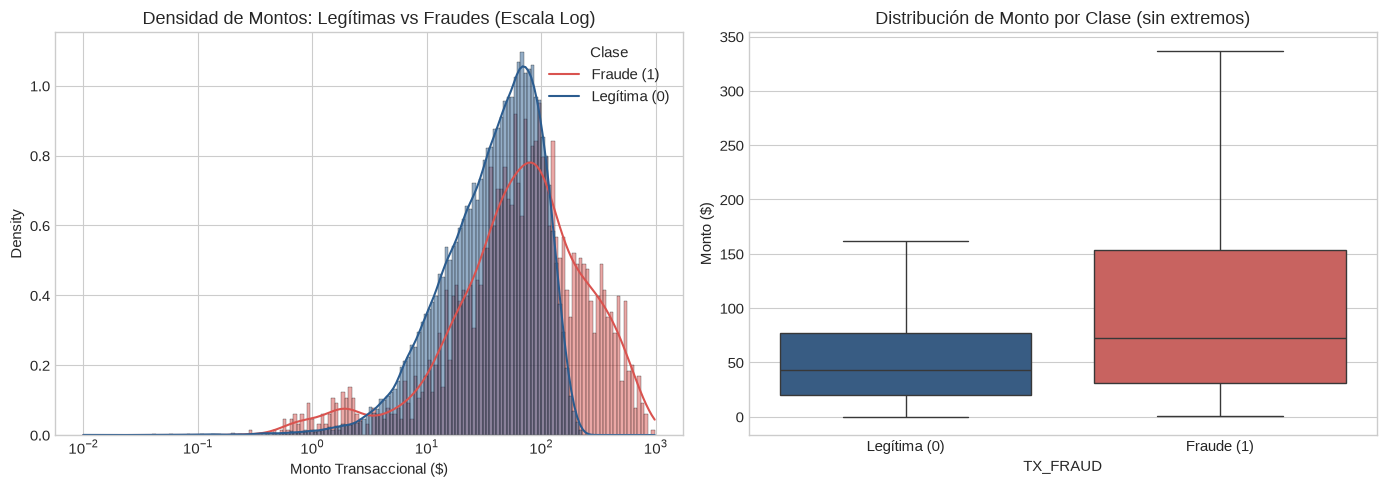

In [7]:
# Paso 2.3: Visualización 1 - Distribución general de montos (Escala Logarítmica)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de densidad (KDE)
sns.histplot(
    data=df_raw[df_raw['TX_AMOUNT'] > 0],
    x='TX_AMOUNT',
    hue='TX_FRAUD',
    palette=['#2b5c8f', '#d9534f'],
    log_scale=True,
    kde=True,
    stat='density',
    common_norm=False,
    ax=axes[0]
)
axes[0].set_title("Densidad de Montos: Legítimas vs Fraudes (Escala Log)")
axes[0].set_xlabel("Monto Transaccional ($)")
axes[0].legend(title="Clase", labels=['Fraude (1)', 'Legítima (0)'])

# Diagrama de caja general
sns.boxplot(
    data=df_raw[df_raw['TX_AMOUNT'] > 0],
    x='TX_FRAUD',
    y='TX_AMOUNT',
    hue='TX_FRAUD',
    palette=['#2b5c8f', '#d9534f'],
    ax=axes[1],
    legend=False,
    showfliers=False
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Legítima (0)', 'Fraude (1)'])
axes[1].set_title("Distribución de Monto por Clase (sin extremos)")
axes[1].set_ylabel("Monto ($)")

plt.tight_layout()
plt.show()


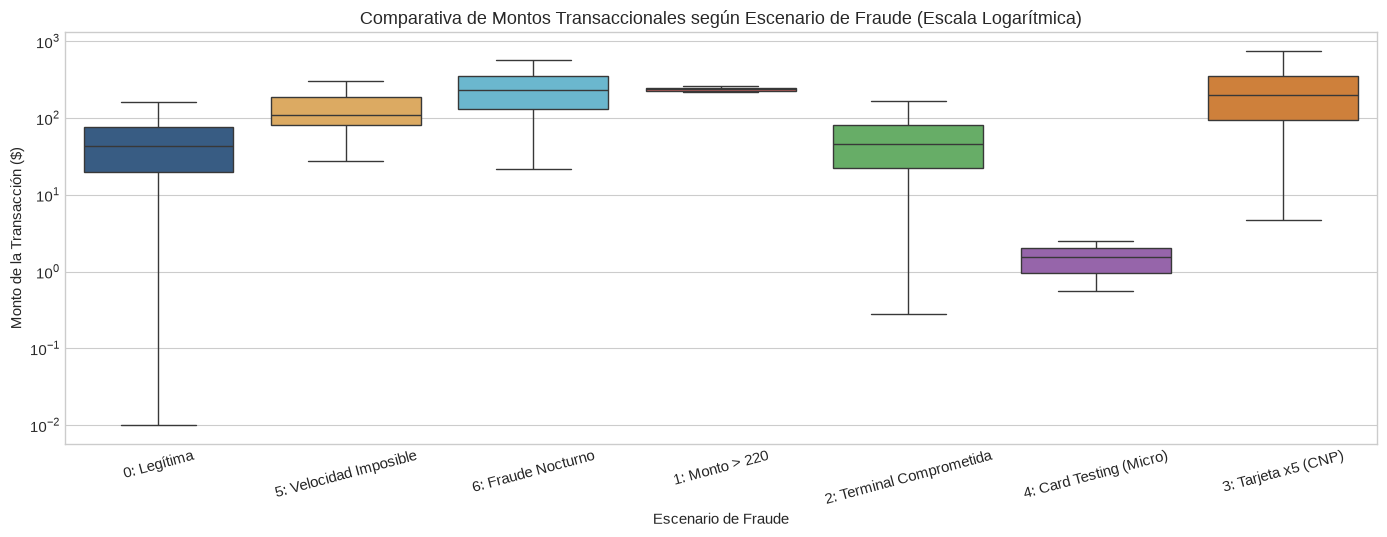

In [8]:
# Paso 2.4: Visualización 2 - Perfil de montos según los 6 Escenarios de Fraude
scenario_names = {
    0: '0: Legítima',
    1: '1: Monto > 220',
    2: '2: Terminal Comprometida',
    3: '3: Tarjeta x5 (CNP)',
    4: '4: Card Testing (Micro)',
    5: '5: Velocidad Imposible',
    6: '6: Fraude Nocturno'
}

df_plot_scenarios = df_raw[df_raw['TX_AMOUNT'] > 0].copy()
df_plot_scenarios['Escenario_Desc'] = df_plot_scenarios['TX_FRAUD_SCENARIO'].map(scenario_names)

plt.figure(figsize=(14, 5.5))
palette_scenarios = ['#2b5c8f', '#f0ad4e', '#5bc0de', '#d9534f', '#5cb85c', '#9b59b6', '#e67e22']
sns.boxplot(
    data=df_plot_scenarios,
    x='Escenario_Desc',
    y='TX_AMOUNT',
    hue='Escenario_Desc',
    palette=palette_scenarios,
    legend=False,
    showfliers=False
)
plt.yscale('log')
plt.title("Comparativa de Montos Transaccionales según Escenario de Fraude (Escala Logarítmica)")
plt.xlabel("Escenario de Fraude")
plt.ylabel("Monto de la Transacción ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


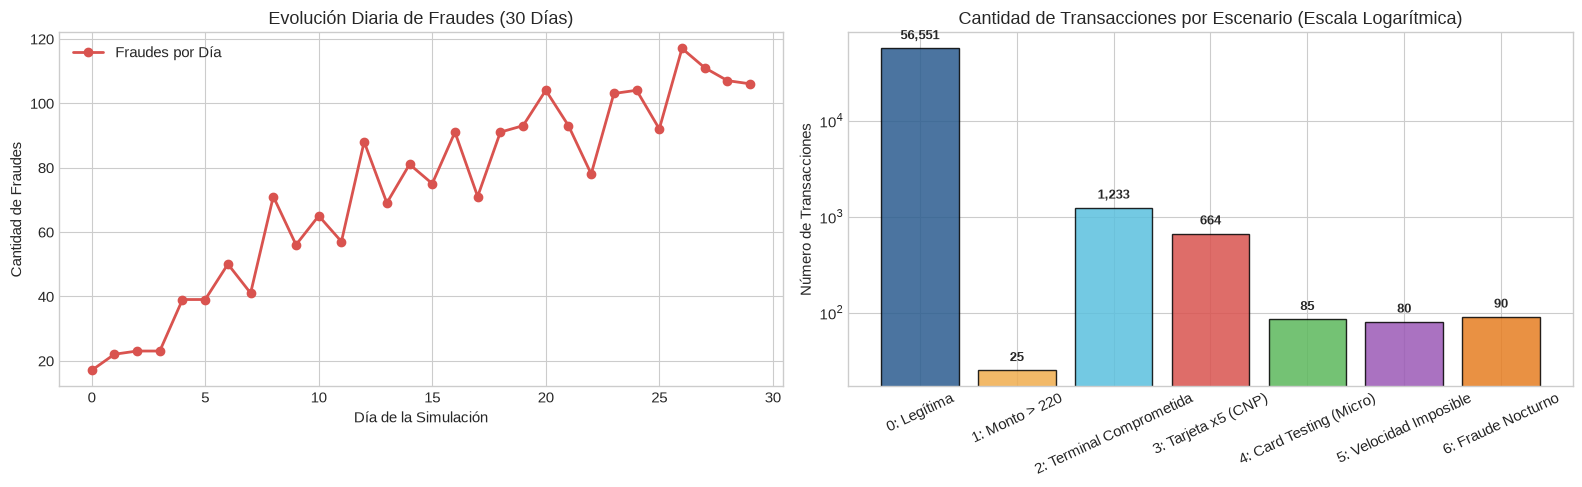

In [9]:
# Paso 2.5: Visualización 3 - Análisis Temporal y Volumen por Escenario
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# A) Evolución temporal a lo largo de los días
daily_stats = df_raw.groupby('TX_TIME_DAYS')['TX_FRAUD'].agg(['count', 'sum'])
axes[0].plot(daily_stats.index, daily_stats['sum'], color='#d9534f', marker='o', lw=2, label='Fraudes por Día')
axes[0].set_title("Evolución Diaria de Fraudes (30 Días)")
axes[0].set_xlabel("Día de la Simulación")
axes[0].set_ylabel("Cantidad de Fraudes")
axes[0].legend()

# B) Conteo de transacciones por escenario en escala logarítmica
sc_counts = df_raw['TX_FRAUD_SCENARIO'].value_counts().sort_index()
sc_labels = [scenario_names.get(i, str(i)) for i in sc_counts.index]

axes[1].bar(sc_labels, sc_counts.values, color=palette_scenarios, edgecolor='black', alpha=0.85)
axes[1].set_yscale('log')
axes[1].set_title("Cantidad de Transacciones por Escenario (Escala Logarítmica)")
axes[1].set_ylabel("Número de Transacciones")
axes[1].tick_params(axis='x', rotation=25)
for i, v in enumerate(sc_counts.values):
    axes[1].text(i, v * 1.25, f"{v:,}", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


### Conclusiones del Análisis Exploratorio (EDA):
1. **Heterogeneidad de Montos:** El **Escenario 4 (Card Testing)** exhibe montos diminutos ($< \$3$), mientras que el **Escenario 1** y **Escenario 3** presentan montos masivos. Esto demuestra por qué una simple regla de "monto alto" es insuficiente.
2. **Desbalance Estructurado:** El fraude representa aproximadamente el $3.7\%$ del volumen total transaccional.
3. **Implicación para Modelado:** Un modelo que dependa exclusivamente del monto ignorará el Escenario 4 y confundirá las compras normales del Escenario 2, haciendo indispensable la ingeniería de características de contexto y velocidad.


---
## Migración del Pipeline de Modelado a Script (`train.py`)

Siguiendo las directrices del proyecto y las mejores prácticas de MLOps:
- Este notebook se conserva **únicamente para la exploración de datos (EDA)**, inspección inicial y comprensión taxonómica de los escenarios de fraude.
- Toda la lógica de **limpieza, extracción de características, partición temporal, entrenamiento de modelos, evaluación exhaustiva y tracking con MLflow** ha sido desacoplada y migrada al script ejecutable y parametrizable [`train.py`](../train.py).

### Ejecución del Script Parametrizado
El script expone hiperparámetros vía CLI (`argparse`) y fija la semilla aleatoria para garantizar reproducibilidad:
```bash
# Ejecución por defecto con hiperparámetros baseline
uv run python train.py

# Ejecución parametrizada (ejemplo de regularización L1)
uv run python train.py --C 0.1 --penalty l1 --solver liblinear --class-weight balanced --random-state 42
```
